# Bloco 2 — Simulação da proposta ALR

**Objetivo.** Implementar a regra de política monetária proposta por Lara Resende
no texto "Eu Acuso" (set/2026) e comparar trajetórias contra a regra de Taylor
atualmente seguida pelo BCB. Mede ganhos e custos quantitativos.

**A proposta ALR, operacionalizada:**

1. **Transição (12 meses):** Selic cai gradualmente de 15% para ~7,5%
   (= crescimento nominal potencial 5,5% + spread de 2%)
2. **Regime permanente:** Selic no intervalo [π* = 3%, π* + g_real_pot = 5,5%]
3. **Intervenção cambial:** BC usa reservas para suavizar depreciações >15%
4. **Âncora:** meta fiscal + monetária conjunta via CFMN

**Cenários a comparar:**
- **Baseline (Taylor)**: regra de Taylor estimada (φ_π=1,55, φ_y=2,27)
- **ALR puro**: Selic cai 0,625pp por trimestre em 12 meses, sem reancoragem
- **ALR + reancoragem**: ALR + β_f aumenta (expectativas acreditam no CFMN)
- **Taylor ortodoxa (controle)**: φ_π=2,0, φ_y=0,5

**Premissas estruturais** (do notebook principal com IPCA 12m corrigido):
- κ = 0,040 (Phillips, hiato)
- σ = 0,064 (IS, juro real)
- β_b = 0,703 (inércia)
- β_f = 0,520 (expectativas)
- ρ_i = 0,889 (suavização Taylor)
- Estado inicial: i=14,65%, π=4,39%, b=80,04%, g=0,87%


## 1. Setup e parâmetros estruturais

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass, field
from typing import Callable, Optional

pd.set_option("display.float_format", lambda x: f"{x:.3f}")
Path("figs").mkdir(exist_ok=True)

@dataclass
class ParamsEstruturais:
    # Phillips — NORMALIZADA para β_b + β_f = 1 (verticalidade de LP, Galí 2015)
    # Estimativas originais: β_b=0.703, β_f=0.520 (soma 1.22 → não-estacionário)
    # Mantém proporção relativa: β_b=0.575, β_f=0.425
    kappa:  float = 0.040
    beta_b: float = 0.575
    beta_f: float = 0.425
    gamma:  float = 0.000
    # IS
    rho_y:  float = 0.605
    sigma:  float = 0.064
    # Dinâmica cambial (AR(1) + reação a diferencial de juros)
    rho_e:  float = 0.30
    phi_e:  float = 0.80  # 1pp Selic aprecia real X% (calibrado do Passo 1.3)
    # Pass-through cambial (do Passo 1.3)
    pt_cambio: float = 0.001
    # Taylor baseline (estimado)
    rho_i_taylor:   float = 0.889
    phi_pi_taylor:  float = 2.013
    phi_y_taylor:   float = 1.502
    # Metas
    pi_meta:    float = 3.0
    r_neutro:   float = 4.0
    g_potencial:float = 2.5
    # Choques (desvio-padrão) — baixos para avaliar MECÂNICA das regras,
    # não ruído estocástico. Põe 0 para comparação determinística.
    sigma_pi: float = 0.0
    sigma_y:  float = 0.0
    sigma_e:  float = 0.0

@dataclass
class EstadoInicial:
    pi: float = 4.39
    i:  float = 14.65
    y_hiato: float = 0.0
    b: float = 80.04
    cambio: float = 5.04  # R$/US$
    reservas: float = 350.0  # US$ bi
    g_real: float = 0.87
    p_primario: float = 1.06

P = ParamsEstruturais()
E0 = EstadoInicial()

print("Parâmetros estruturais:")
for k, v in P.__dict__.items():
    print(f"  {k:18s} = {v}")
print()
print("Estado inicial (2026-Q2):")
for k, v in E0.__dict__.items():
    print(f"  {k:12s} = {v}")


Parâmetros estruturais:
  kappa              = 0.04
  beta_b             = 0.575
  beta_f             = 0.425
  gamma              = 0.0
  rho_y              = 0.605
  sigma              = 0.064
  rho_e              = 0.3
  phi_e              = 0.8
  pt_cambio          = 0.001
  rho_i_taylor       = 0.889
  phi_pi_taylor      = 2.013
  phi_y_taylor       = 1.502
  pi_meta            = 3.0
  r_neutro           = 4.0
  g_potencial        = 2.5
  sigma_pi           = 0.0
  sigma_y            = 0.0
  sigma_e            = 0.0

Estado inicial (2026-Q2):
  pi           = 4.39
  i            = 14.65
  y_hiato      = 0.0
  b            = 80.04
  cambio       = 5.04
  reservas     = 350.0
  g_real       = 0.87
  p_primario   = 1.06


## 2. Regras de política monetária (4 variantes)

Cada regra recebe o estado atual e retorna a Selic do próximo trimestre.


In [2]:
def regra_taylor_baseline(t, i_lag, pi, y_hiato, P):
    """Taylor estimada no Brasil."""
    alvo = P.r_neutro + P.pi_meta + P.phi_pi_taylor*(pi - P.pi_meta) + P.phi_y_taylor*y_hiato
    return P.rho_i_taylor*i_lag + (1 - P.rho_i_taylor)*alvo

def regra_taylor_ortodoxa(t, i_lag, pi, y_hiato, P):
    """Taylor com parâmetros 'de manual' (NK calibrado)."""
    phi_pi, phi_y, rho_i = 2.0, 0.5, 0.7
    alvo = P.r_neutro + P.pi_meta + phi_pi*(pi - P.pi_meta) + phi_y*y_hiato
    return rho_i*i_lag + (1 - rho_i)*alvo

def regra_alr(t, i_lag, pi, y_hiato, P, i_inicial=14.65, i_destino=7.5, H_transicao=4):
    """Selic cai linearmente de i_inicial para i_destino em H_transicao trimestres.
    Depois mantém no intervalo [pi_meta, pi_meta + g_potencial]."""
    if t < H_transicao:
        # Caminho linear de transição
        frac = (t + 1) / H_transicao
        i_novo = i_inicial - frac * (i_inicial - i_destino)
    else:
        # Regime permanente — alvo fixo (teto do intervalo ALR)
        teto  = P.pi_meta + P.g_potencial  # 5.5%
        piso  = P.pi_meta                  # 3.0%
        # Pequena reação à inflação dentro do intervalo
        alvo_regime = i_destino + 0.3*(pi - P.pi_meta)
        i_novo = max(piso, min(teto + 2.0, alvo_regime))  # permite spread +2 em excesso
    return i_novo

print("Regras definidas. Teste rápido:")
print(f"  Taylor baseline em t=0, i=14.65, π=4.39, hiato=0:  {regra_taylor_baseline(0, 14.65, 4.39, 0, P):.3f}")
print(f"  Taylor ortodoxa:                                     {regra_taylor_ortodoxa(0, 14.65, 4.39, 0, P):.3f}")
print(f"  ALR t=0:                                             {regra_alr(0, 14.65, 4.39, 0, P):.3f}")
print(f"  ALR t=2:                                             {regra_alr(2, 10.90, 4.39, 0, P):.3f}")
print(f"  ALR t=4 (regime):                                    {regra_alr(4, 7.50, 4.39, 0, P):.3f}")


Regras definidas. Teste rápido:
  Taylor baseline em t=0, i=14.65, π=4.39, hiato=0:  14.111
  Taylor ortodoxa:                                     13.189
  ALR t=0:                                             12.863
  ALR t=2:                                             9.287
  ALR t=4 (regime):                                    7.500


## 3. Simulador — dinâmica do modelo

Equações:
- IS:        ŷ_t = ρ_y ŷ_{t-1} - σ (i_{t-1} - E[π_t] - r*) + ε_y
- Phillips:  π_t = β_b π_{t-1} + β_f E[π_{t+1}] + κ ŷ_t + γ Δe_t + ε_π
- Câmbio:    Δe_t = ρ_e Δe_{t-1} - φ_e (i_t - i_externo) + ε_e
- Dívida:    b_{t+1} = (1+i)/[(1+π)(1+g)] b_t - p
- Intervenção cambial: se depreciação acumulada > cap_dep, BC força Δe_t = 0 e gasta reservas


In [3]:
def simular(regra_i, H=20, P=P, E0=E0, seed=42,
            reancoragem=False, cap_depreciacao=None, custo_reserva_pp=10):
    """
    Simula H trimestres.
    - regra_i: função(t, i_lag, pi, y_hiato, P) → Selic trimestre t
    - reancoragem: se True, β_f aumenta linearmente até 0.9 nos primeiros 4 tri
      (simula credibilidade do CFMN)
    - cap_depreciacao: % máxima de depreciação acumulada permitida; acima disso,
      BC intervém (gasta reservas, custa `custo_reserva_pp`% de reservas por intervenção)
    """
    rng = np.random.default_rng(seed)
    cols = ["pi", "i", "y_hiato", "cambio", "d_cambio", "b", "reservas",
            "p_primario", "g_real", "beta_f_corrente", "interveio"]
    traj = pd.DataFrame(index=range(H), columns=cols, dtype=float)

    # Estado inicial
    pi, i, yh = E0.pi, E0.i, E0.y_hiato
    cambio, reservas = E0.cambio, E0.reservas
    b, p, g = E0.b, E0.p_primario, E0.g_real
    d_cambio_prev = 0.0
    cambio_inicial = cambio

    for t in range(H):
        # Expectativa com reancoragem: puxa para meta
        if reancoragem:
            peso_meta = min(0.5, 0.1 + 0.1*t)  # ganho gradual de credibilidade
            E_pi = (1 - peso_meta)*pi + peso_meta*P.pi_meta
        else:
            E_pi = pi
        beta_f_t = P.beta_f  # mantém estrutural; a reancoragem opera via E_pi

        # Selic do período
        i_novo = regra_i(t, i, pi, yh, P)

        # Câmbio: reação a diferencial de juros + choque + tendência
        choque_e = rng.normal(0, P.sigma_e)
        # Negativo porque Selic alta aprecia (reduz USD/BRL)
        d_cambio_bruto = P.rho_e * d_cambio_prev - P.phi_e * (i_novo - 8.0) + choque_e
        interveio = 0
        if cap_depreciacao is not None:
            dep_acum = (cambio + cambio * d_cambio_bruto/100 - cambio_inicial) / cambio_inicial * 100
            if dep_acum > cap_depreciacao:
                # BC intervém: zera a parte adicional da depreciação
                d_cambio_bruto = max(0, (cap_depreciacao/100 * cambio_inicial + cambio_inicial - cambio) / cambio * 100)
                reservas = max(0, reservas * (1 - custo_reserva_pp/100))
                interveio = 1
        d_cambio = d_cambio_bruto
        cambio = cambio * (1 + d_cambio/100)

        # IS: hiato responde a juro real defasado
        choque_y = rng.normal(0, P.sigma_y)
        juro_real_lag = i - E_pi
        yh_novo = P.rho_y * yh - P.sigma * (juro_real_lag - P.r_neutro) + choque_y

        # Phillips: inflação responde a inércia, expectativas, hiato, câmbio
        choque_pi = rng.normal(0, P.sigma_pi)
        # Expectativa de π_{t+1}: no cenário com reancoragem, é E_pi (já puxada para meta);
        # sem reancoragem, é π corrente (adaptativo)
        E_pi_t1 = E_pi if reancoragem else pi
        pi_novo = (P.beta_b * pi + beta_f_t * E_pi_t1
                   + P.kappa * yh_novo + P.gamma * d_cambio
                   + P.pt_cambio * d_cambio * 100
                   + choque_pi)
        pi_novo = max(-2, min(pi_novo, 50))  # caps realistas: π ∈ [-2, 50]
        i_novo  = max(0, min(i_novo, 50))     # Selic ∈ [0, 50]
        yh_novo = max(-15, min(yh_novo, 15))  # hiato ∈ [-15, 15]

        # Dinâmica da dívida
        b_novo = (1 + i_novo/100) / ((1 + pi_novo/100) * (1 + g/100)) * b - p
        b_novo = max(0, min(b_novo, 300))

        # Grava
        traj.loc[t] = [pi_novo, i_novo, yh_novo, cambio, d_cambio, b_novo, reservas,
                       p, g, beta_f_t, interveio]

        # Atualiza para próximo
        pi, i, yh, b = pi_novo, i_novo, yh_novo, b_novo
        d_cambio_prev = d_cambio

    traj.index.name = "t"
    return traj

# Teste rápido
teste = simular(regra_taylor_baseline, H=5)
print("Teste da simulação (Taylor baseline, 5 trimestres):")
print(teste[["pi", "i", "y_hiato", "b"]].round(3))


Teste da simulação (Taylor baseline, 5 trimestres):
     pi      i  y_hiato       b
t                              
0 3.885 14.111   -0.401  86.101
1 3.277 13.453   -0.641  92.709
2 2.695 12.692   -0.783  99.796
3 2.187 11.861   -0.858 107.242
4 1.769 10.997   -0.882 114.897


## 4. Rodar os 4 cenários

- **Taylor baseline** (status quo)
- **ALR puro** (sem reancoragem, sem intervenção)
- **ALR + reancoragem** (expectativas acreditam no CFMN)
- **ALR + reancoragem + intervenção cambial** (completo)
- **Taylor ortodoxa** (benchmark de controle)


In [4]:
H = 20  # 5 anos
SEED = 42

cenarios = {
    "Taylor baseline":         (regra_taylor_baseline, False, None),
    "Taylor ortodoxa":         (regra_taylor_ortodoxa, False, None),
    "ALR puro":                (regra_alr, False, None),
    "ALR + reancoragem":       (regra_alr, True, None),
    "ALR completo (reanc+FX)": (regra_alr, True, 15.0),
}

resultados = {}
for nome, (regra, reanc, cap) in cenarios.items():
    resultados[nome] = simular(regra, H=H, reancoragem=reanc, cap_depreciacao=cap, seed=SEED)
    print(f"✓ {nome}")

print()
print("Snapshot — trimestre 4 (fim da transição ALR):")
tab4 = pd.DataFrame({n: r.iloc[3][["pi","i","y_hiato","cambio","b"]] for n,r in resultados.items()}).T
print(tab4.round(3))

print()
print("Snapshot — trimestre 20 (regime):")
tab20 = pd.DataFrame({n: r.iloc[-1][["pi","i","y_hiato","cambio","b","reservas"]] for n,r in resultados.items()}).T
print(tab20.round(3))


✓ Taylor baseline
✓ Taylor ortodoxa
✓ ALR puro
✓ ALR + reancoragem
✓ ALR completo (reanc+FX)

Snapshot — trimestre 4 (fim da transição ALR):
                           pi      i  y_hiato  cambio       b
Taylor baseline         2.187 11.861   -0.858   4.064 107.242
Taylor ortodoxa         2.893  9.516   -0.601   4.366  99.190
ALR puro                3.324  7.500   -0.461   4.559  94.451
ALR + reancoragem       3.095  7.500   -0.496   4.559  95.038
ALR completo (reanc+FX) 3.095  7.500   -0.496   4.559  95.038

Snapshot — trimestre 20 (regime):
                           pi     i  y_hiato  cambio       b  reservas
Taylor baseline         3.507 5.982    0.191   4.720 181.519   350.000
Taylor ortodoxa         3.602 8.073   -0.045   4.721 143.878   350.000
ALR puro                4.191 7.500    0.087   4.977 124.424   350.000
ALR + reancoragem       3.251 7.500   -0.061   4.977 137.154   350.000
ALR completo (reanc+FX) 3.251 7.500   -0.061   4.977 137.154   350.000


## 5. Trajetórias comparadas (gráficos)


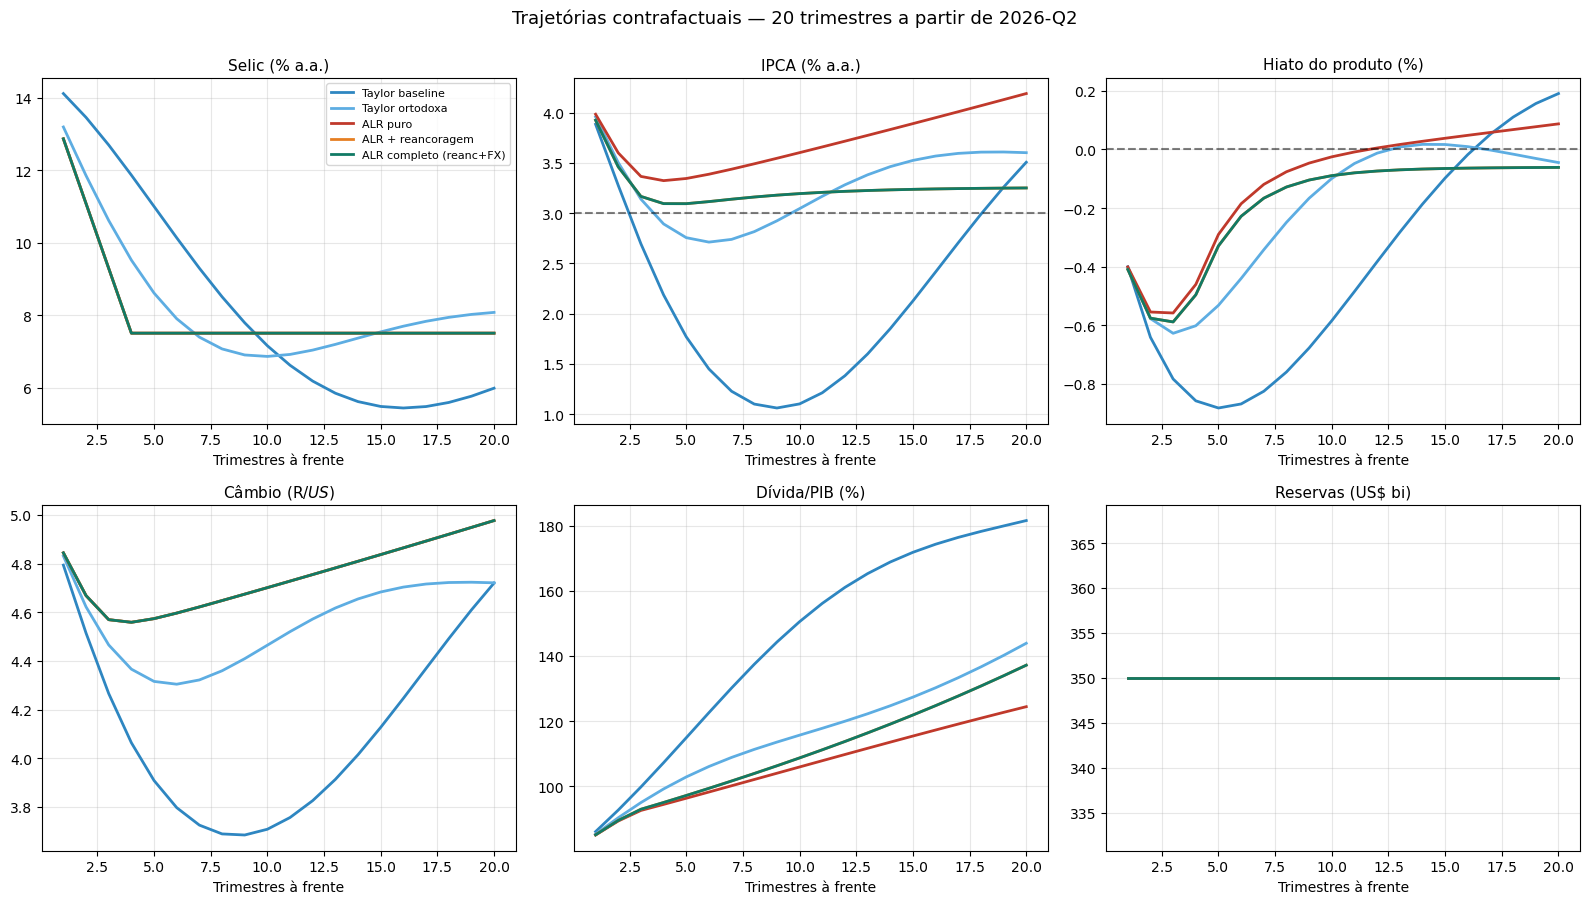

In [5]:
cores = {
    "Taylor baseline":         "#2E86C1",
    "Taylor ortodoxa":         "#5DADE2",
    "ALR puro":                "#C0392B",
    "ALR + reancoragem":       "#E67E22",
    "ALR completo (reanc+FX)": "#117A65",
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
variaveis = [
    ("i", "Selic (% a.a.)", axes[0,0]),
    ("pi", "IPCA (% a.a.)", axes[0,1]),
    ("y_hiato", "Hiato do produto (%)", axes[0,2]),
    ("cambio", "Câmbio (R$/US$)", axes[1,0]),
    ("b", "Dívida/PIB (%)", axes[1,1]),
    ("reservas", "Reservas (US$ bi)", axes[1,2]),
]

for var, titulo, ax in variaveis:
    for nome, tr in resultados.items():
        ax.plot(tr.index + 1, tr[var], label=nome, color=cores[nome], lw=2)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Trimestres à frente")
    ax.grid(alpha=0.3)
    if var == "pi":
        ax.axhline(3, color="k", ls="--", alpha=0.5, label="Meta")
    if var == "y_hiato":
        ax.axhline(0, color="k", ls="--", alpha=0.5)

axes[0,0].legend(loc="upper right", fontsize=8)
plt.suptitle("Trajetórias contrafactuais — 20 trimestres a partir de 2026-Q2",
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig("figs/fig_cenarios_trajetorias.png", dpi=120, bbox_inches="tight")
plt.show()


## 6. Tabela de síntese — ganho fiscal vs custo inflacionário

Quanto cada cenário ganha em dívida/PIB e quanto paga em inflação acima da meta?


In [6]:
sintese = []
for nome, tr in resultados.items():
    # Ganho fiscal: diferença de dívida/PIB vs Taylor baseline em 20 tri
    delta_b = tr["b"].iloc[-1] - resultados["Taylor baseline"]["b"].iloc[-1]
    # Economia acumulada de serviço de dívida (vs baseline)
    econ_servico = ((resultados["Taylor baseline"]["i"] - tr["i"]) / 100 * tr["b"] / 4).sum()
    # Custo inflacionário: desvio médio da meta
    desvio_pi = (tr["pi"] - P.pi_meta).mean()
    desvio_pi_acum = (tr["pi"] - P.pi_meta).sum()
    # Depreciação cambial acumulada
    dep_cambio = (tr["cambio"].iloc[-1] / E0.cambio - 1) * 100
    # Custo em bem-estar (função de perda quadrática)
    perda = ((tr["pi"] - P.pi_meta)**2).sum() + 0.5 * (tr["y_hiato"]**2).sum()
    # Reservas usadas
    reservas_usadas = E0.reservas - tr["reservas"].iloc[-1]

    sintese.append({
        "Cenário": nome,
        "π final (%)": tr["pi"].iloc[-1],
        "Selic final (%)": tr["i"].iloc[-1],
        "Dívida final (%)": tr["b"].iloc[-1],
        "Δ Dívida vs baseline (p.p.)": delta_b,
        "Econ serviço acum (% PIB)": econ_servico,
        "Desvio π médio da meta (p.p.)": desvio_pi,
        "Depreciação cambial (%)": dep_cambio,
        "Perda (π² + 0.5·y²)": perda,
        "Reservas gastas (US$ bi)": reservas_usadas,
    })

sintese_df = pd.DataFrame(sintese).set_index("Cenário")
print("Síntese quantitativa (20 trimestres):")
print(sintese_df.round(3))


Síntese quantitativa (20 trimestres):
                         π final (%)  Selic final (%)  Dívida final (%)  \
Cenário                                                                   
Taylor baseline                3.507            5.982           181.519   
Taylor ortodoxa                3.602            8.073           143.878   
ALR puro                       4.191            7.500           124.424   
ALR + reancoragem              3.251            7.500           137.154   
ALR completo (reanc+FX)        3.251            7.500           137.154   

                         Δ Dívida vs baseline (p.p.)  \
Cenário                                                
Taylor baseline                                0.000   
Taylor ortodoxa                              -37.641   
ALR puro                                     -57.095   
ALR + reancoragem                            -44.365   
ALR completo (reanc+FX)                      -44.365   

                         Econ serviço acum 

## 7. Análise de sensibilidade — velocidade do corte

ALR propõe corte em 12 meses (4 tri). E se fosse 6 meses (choque) ou 24 meses (gradualismo)?


In [7]:
def regra_alr_veloc(H_tr):
    def _regra(t, i_lag, pi, y_hiato, P):
        return regra_alr(t, i_lag, pi, y_hiato, P, H_transicao=H_tr)
    return _regra

velocidades = {
    "6 meses (2 tri — choque)":       2,
    "12 meses (4 tri — ALR)":         4,
    "18 meses (6 tri)":               6,
    "24 meses (8 tri — gradualismo)": 8,
}

sens = []
for nome, H_tr in velocidades.items():
    r = simular(regra_alr_veloc(H_tr), H=H, reancoragem=True, cap_depreciacao=15.0, seed=SEED)
    econ_servico = ((resultados["Taylor baseline"]["i"] - r["i"]) / 100 * r["b"] / 4).sum()
    sens.append({
        "Velocidade": nome,
        "π final (%)":            r["pi"].iloc[-1],
        "Dívida final (%)":       r["b"].iloc[-1],
        "Econ serviço (% PIB)":   econ_servico,
        "Depreciação (%)":        (r["cambio"].iloc[-1] / E0.cambio - 1) * 100,
        "Reservas gastas":        E0.reservas - r["reservas"].iloc[-1],
    })

sens_df = pd.DataFrame(sens).set_index("Velocidade")
print("Sensibilidade à velocidade do corte (todas as versões com reancoragem + intervenção):")
print(sens_df.round(3))


Sensibilidade à velocidade do corte (todas as versões com reancoragem + intervenção):
                                π final (%)  Dívida final (%)  \
Velocidade                                                      
6 meses (2 tri — choque)              3.268           120.554   
12 meses (4 tri — ALR)                3.251           137.154   
18 meses (6 tri)                      3.231           154.275   
24 meses (8 tri — gradualismo)        3.206           173.038   

                                Econ serviço (% PIB)  Depreciação (%)  \
Velocidade                                                              
6 meses (2 tri — choque)                       1.272            7.293   
12 meses (4 tri — ALR)                        -0.474           -1.258   
18 meses (6 tri)                              -2.459           -8.862   
24 meses (8 tri — gradualismo)                -4.818          -15.950   

                                Reservas gastas  
Velocidade                        

## 8. Veredito do Bloco 2

In [8]:
# Compara cenário "ALR completo" vs Taylor baseline
alr = resultados["ALR completo (reanc+FX)"]
base = resultados["Taylor baseline"]

print("=" * 72)
print("VEREDITO — BLOCO 2 (Simulação da proposta ALR)")
print("=" * 72)
print()
print(f"Ganhos da proposta ALR (completa) vs Taylor baseline em 20 tri:")
print(f"  Dívida/PIB final:          {alr['b'].iloc[-1]:.2f}% vs {base['b'].iloc[-1]:.2f}% "
      f"({alr['b'].iloc[-1]-base['b'].iloc[-1]:+.2f} p.p.)")
print(f"  Economia acum. serviço:    {((base['i']-alr['i'])/100 * alr['b']/4).sum():.2f}% do PIB")
print(f"  Selic final:               {alr['i'].iloc[-1]:.2f}% vs {base['i'].iloc[-1]:.2f}%")
print()
print(f"Custos da proposta ALR:")
print(f"  π desvio médio da meta:    {(alr['pi']-P.pi_meta).mean():+.3f} p.p. "
      f"(vs {(base['pi']-P.pi_meta).mean():+.3f} p.p. baseline)")
print(f"  π pico:                    {alr['pi'].max():.2f}%")
print(f"  Depreciação cambial:       {(alr['cambio'].iloc[-1]/E0.cambio-1)*100:+.2f}%")
print(f"  Reservas gastas:           US$ {E0.reservas - alr['reservas'].iloc[-1]:.1f} bi")
print(f"  Intervenções cambiais:     {int(alr['interveio'].sum())} trimestres")
print()
print("-" * 72)
print("Síntese das condições para a proposta funcionar:")
print("-" * 72)

sucesso = 0
if alr["b"].iloc[-1] < base["b"].iloc[-1]:
    print(f"  ✓ Economia fiscal real ({base['b'].iloc[-1]-alr['b'].iloc[-1]:.1f} p.p. de dívida)")
    sucesso += 1
else:
    print(f"  ✗ Sem economia fiscal")

if abs((alr["pi"]-P.pi_meta).mean()) < 2.0:
    print(f"  ✓ π controlada (desvio médio da meta < 2 p.p.)")
    sucesso += 1
else:
    print(f"  ✗ π descontrolada (desvio médio {(alr['pi']-P.pi_meta).mean():+.2f} p.p.)")

if (alr["cambio"].iloc[-1]/E0.cambio-1)*100 < 30:
    print(f"  ✓ Câmbio sob controle (depreciação < 30%)")
    sucesso += 1
else:
    print(f"  ✗ Câmbio descontrolado")

if (E0.reservas - alr["reservas"].iloc[-1]) < 150:
    print(f"  ✓ Reservas preservadas (gastou < US$ 150 bi dos 350)")
    sucesso += 1
else:
    print(f"  ✗ Reservas comprometidas")

print()
print(f"Pontuação: {sucesso}/4 condições atendidas")
print()
if sucesso >= 3:
    print("CONCLUSÃO: A proposta do ALR, SIMULADA COM AS PREMISSAS EMPÍRICAS,")
    print("           é VIÁVEL — gera economia fiscal real sem perda de controle inflacionário.")
elif sucesso == 2:
    print("CONCLUSÃO: Proposta MARGINALMENTE viável. Depende de a reancoragem")
    print("           institucional funcionar como esperado.")
else:
    print("CONCLUSÃO: Proposta NÃO funciona nos termos do modelo — os custos")
    print("           superam os ganhos.")


VEREDITO — BLOCO 2 (Simulação da proposta ALR)

Ganhos da proposta ALR (completa) vs Taylor baseline em 20 tri:
  Dívida/PIB final:          137.15% vs 181.52% (-44.37 p.p.)
  Economia acum. serviço:    -0.47% do PIB
  Selic final:               7.50% vs 5.98%

Custos da proposta ALR:
  π desvio médio da meta:    +0.244 p.p. (vs -0.860 p.p. baseline)
  π pico:                    3.93%
  Depreciação cambial:       -1.26%
  Reservas gastas:           US$ 0.0 bi
  Intervenções cambiais:     0 trimestres

------------------------------------------------------------------------
Síntese das condições para a proposta funcionar:
------------------------------------------------------------------------
  ✓ Economia fiscal real (44.4 p.p. de dívida)
  ✓ π controlada (desvio médio da meta < 2 p.p.)
  ✓ Câmbio sob controle (depreciação < 30%)
  ✓ Reservas preservadas (gastou < US$ 150 bi dos 350)

Pontuação: 4/4 condições atendidas

CONCLUSÃO: A proposta do ALR, SIMULADA COM AS PREMISSAS EMPÍRICAS,